# FastMRI 2026 — 원본 vs 증강 데이터 시각화

`utils/data/` 안의 원본 `*.h5` 와 증강본 `*_aug.h5` 를 나란히 비교한다.

적용된 증강 (테스트 아티팩트, `transforms.py` 실제 코드로 생성):
- **좌-우(width) flip** — image_input/grappa/label · k-space · mask · bbox 전부 동기
- **ACS 보존 마스크 thinning** — 중앙 저주파(ACS)는 유지, 주변부만 추가 언더샘플
- bbox 좌표도 `x' = 384 − x − w` 로 flip

> 실제 학습에선 저장 없이 매 배치 on-the-fly·슬라이스별 랜덤 확률로 적용된다. 이 노트북은 눈으로 확인하기 위한 고정 아티팩트.

In [1]:
import json
from pathlib import Path
import h5py
import numpy as np
import matplotlib
matplotlib.rcParams["font.family"] = "AppleGothic"   # 한글 제목 깨짐 방지 (macOS)
matplotlib.rcParams["axes.unicode_minus"] = False
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

DATA_DIR = Path("utils/data") if Path("utils/data").exists() else Path(".")
IMAGE_KEYS = ("image_input", "image_grappa", "image_label")

def paths(acc, aug=False):
    suf = "_aug" if aug else ""
    img = sorted(DATA_DIR.glob(f"img*acc{acc}_*{suf}.h5"))
    ksp = sorted(DATA_DIR.glob(f"kspace*acc{acc}_*{suf}.h5"))
    img = [p for p in img if ("_aug" in p.name) == aug]
    ksp = [p for p in ksp if ("_aug" in p.name) == aug]
    return img[0], ksp[0]

def load_ann(hf):
    raw = hf.attrs.get("annotations", None)
    return {int(k): v for k, v in json.loads(raw).items()} if raw else {}

def draw_bboxes(ax, bboxes, color="red"):
    for b in bboxes:
        ax.add_patch(Rectangle((b["x"], b["y"]), b["width"], b["height"],
                               linewidth=1.5, edgecolor=color, facecolor="none"))
        ax.text(b["x"], b["y"] - 3, b["label"], color=color, fontsize=6, va="bottom",
                bbox=dict(facecolor="black", alpha=0.4, pad=0.5, edgecolor="none"))
print("helpers ready. files:", [p.name for p in sorted(DATA_DIR.glob("*_aug.h5"))])

helpers ready. files: ['img_knee_acc4_1_aug.h5', 'img_knee_acc8_1_aug.h5', 'kspace_knee_acc4_1_aug.h5', 'kspace_knee_acc8_1_aug.h5']


## 1. 파일 요약 (원본 vs 증강)

In [2]:
for acc in (4, 8):
    (oi, ok), (ai, ak) = paths(acc, False), paths(acc, True)
    with h5py.File(ok) as h: om = int((h["mask"][:] >= 1).sum()); W = h["mask"].shape[0]
    with h5py.File(ak) as h: am = int((h["mask"][:] >= 1).sum())
    with h5py.File(oi) as h: oann = load_ann(h)
    with h5py.File(ai) as h: aann = load_ann(h)
    print(f"acc{acc}: mask sampled {om}->{am} / {W} lines (ACS 보존, 주변부 thinning)")
    print(f"        bbox slices: {sorted(oann)}  (x좌표 flip 반영됨)")

acc4: mask sampled 114->71 / 368 lines (ACS 보존, 주변부 thinning)
        bbox slices: [13, 14, 17]  (x좌표 flip 반영됨)
acc8: mask sampled 74->52 / 372 lines (ACS 보존, 주변부 thinning)
        bbox slices: [15, 16, 29, 30]  (x좌표 flip 반영됨)


## 2. 이미지 비교 — 모든 병변(annotation) 슬라이스

각 슬라이스마다 위=원본, 아래=증강. 좌우 반전과 bbox(레드박스) 위치 이동을 확인.

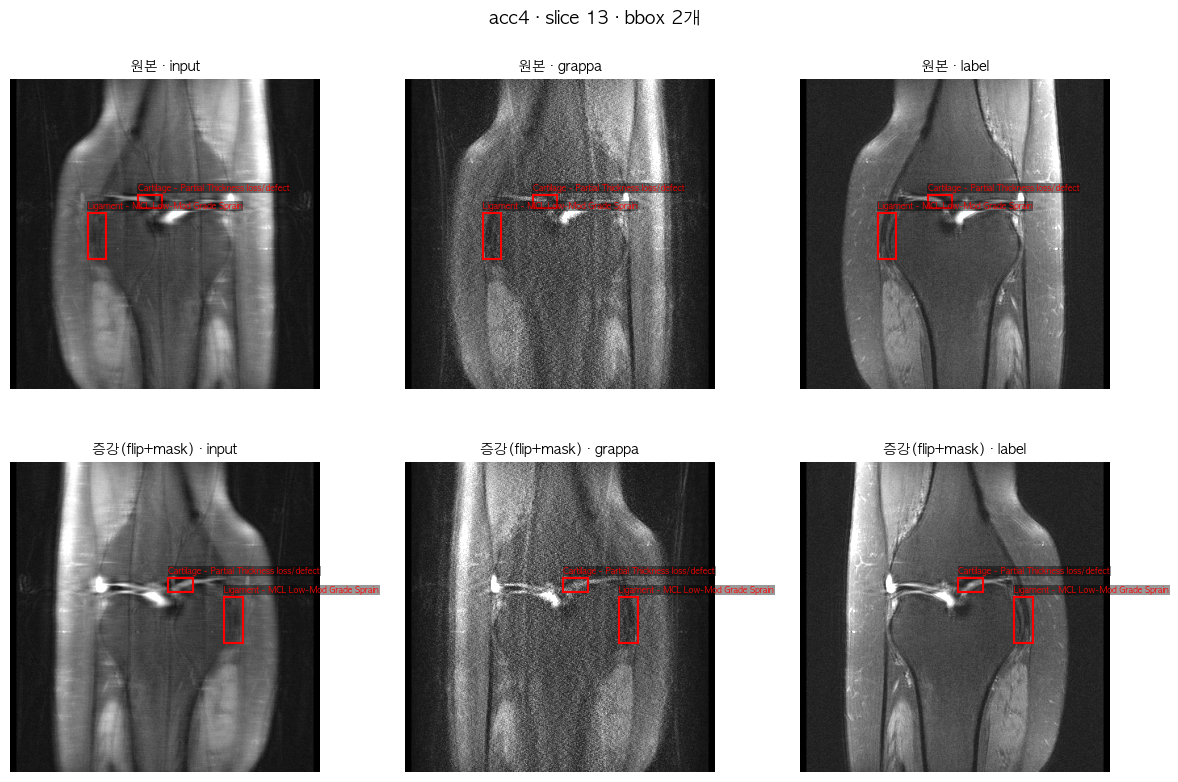

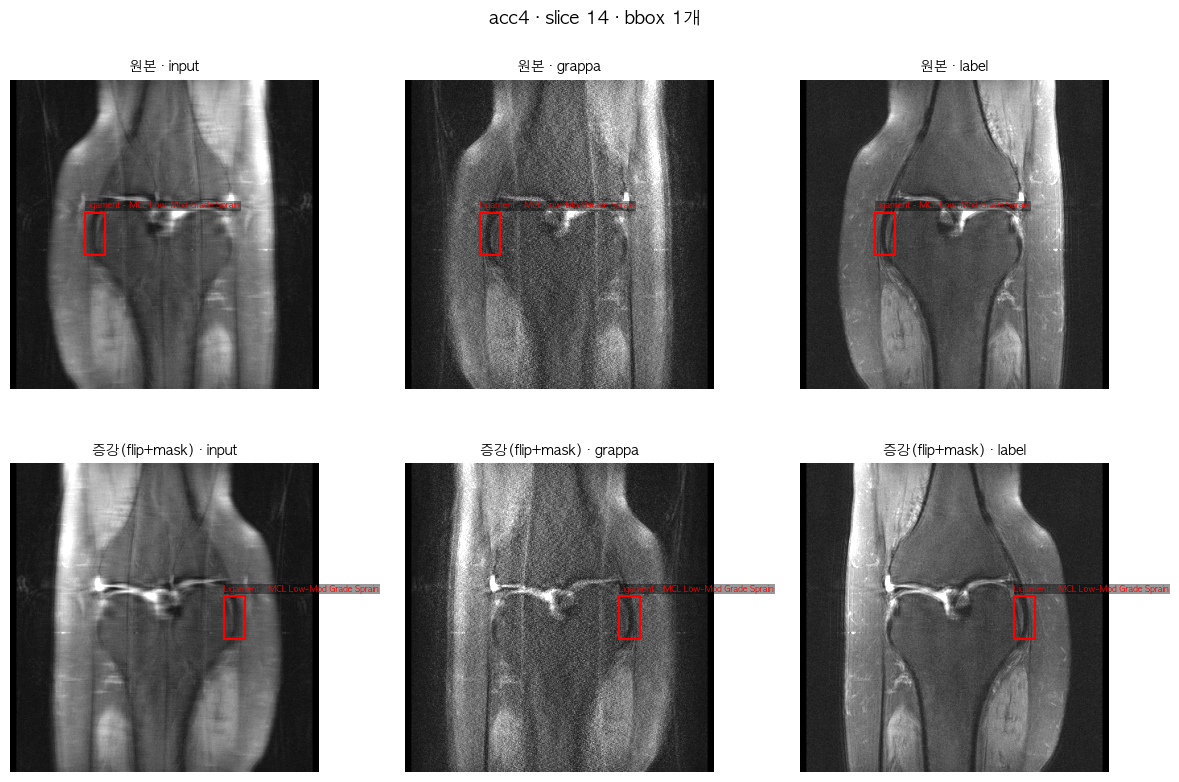

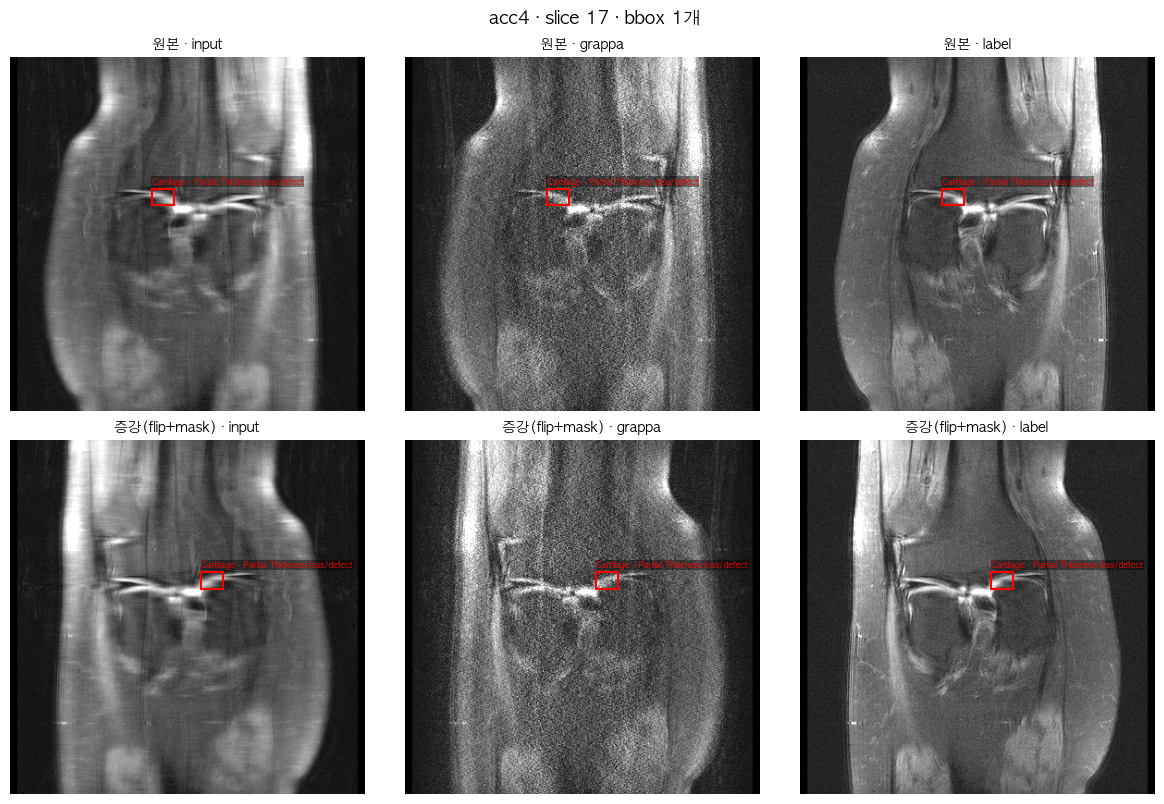

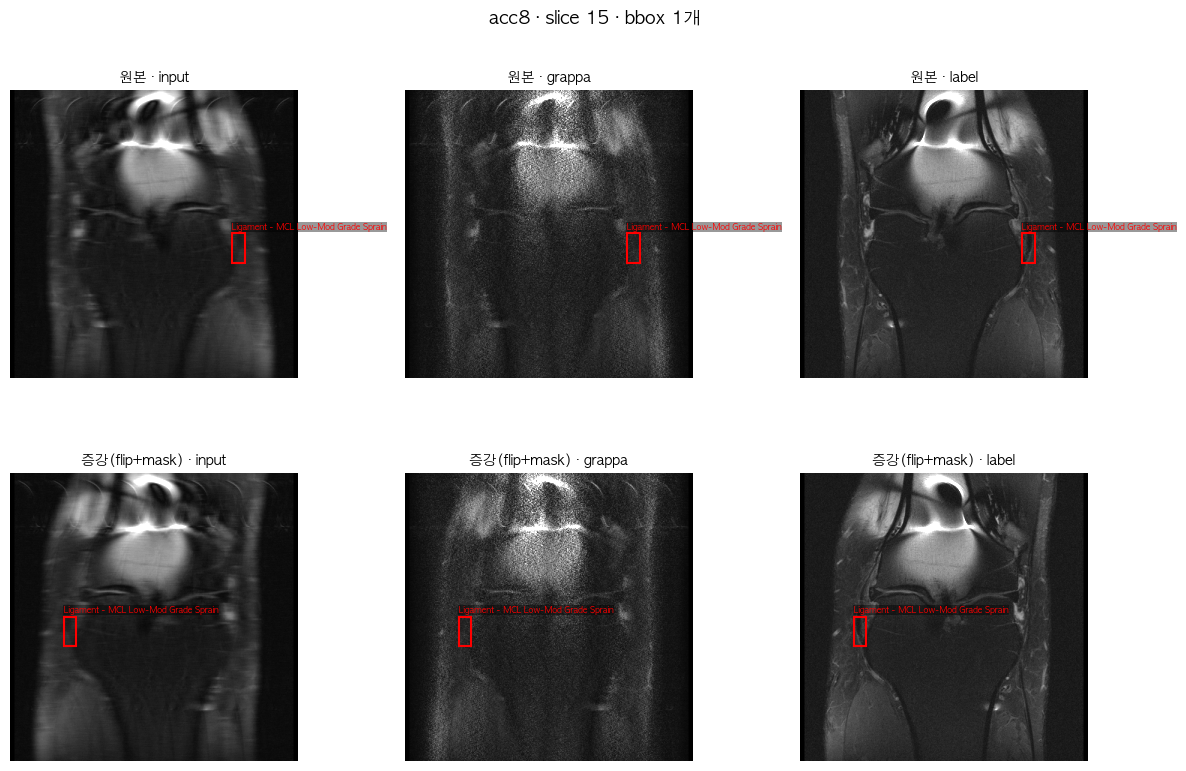

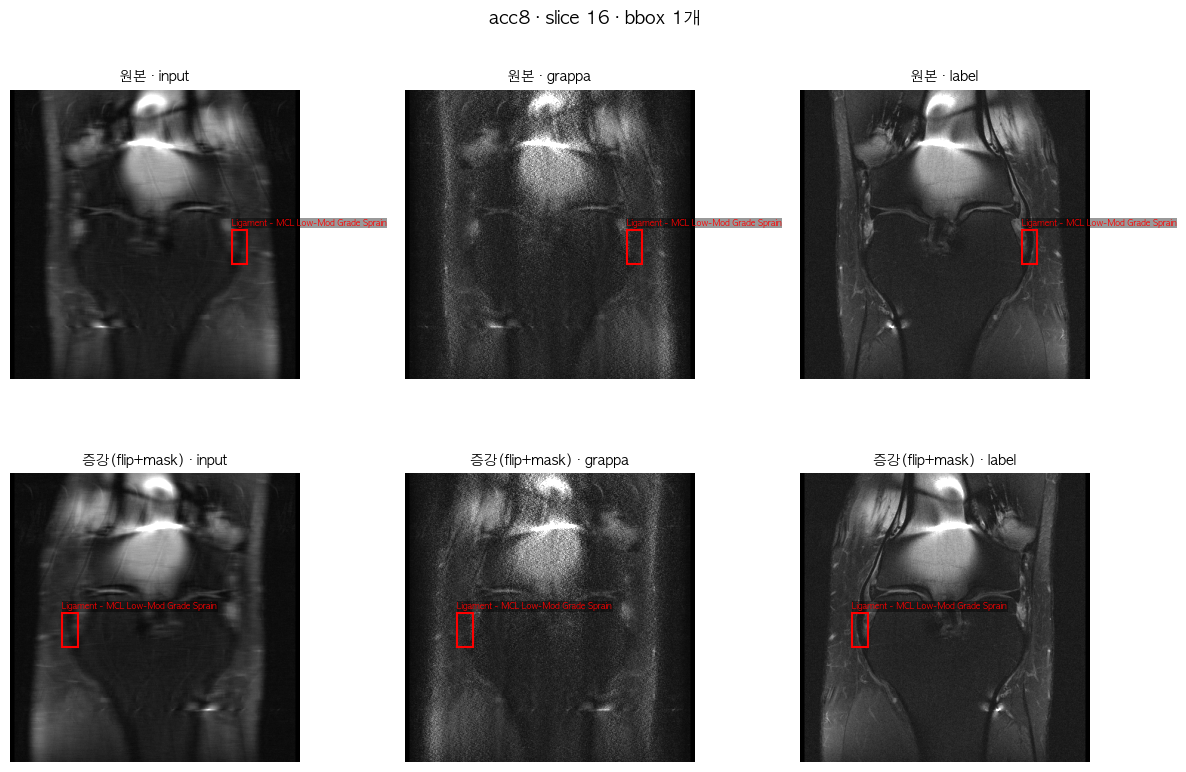

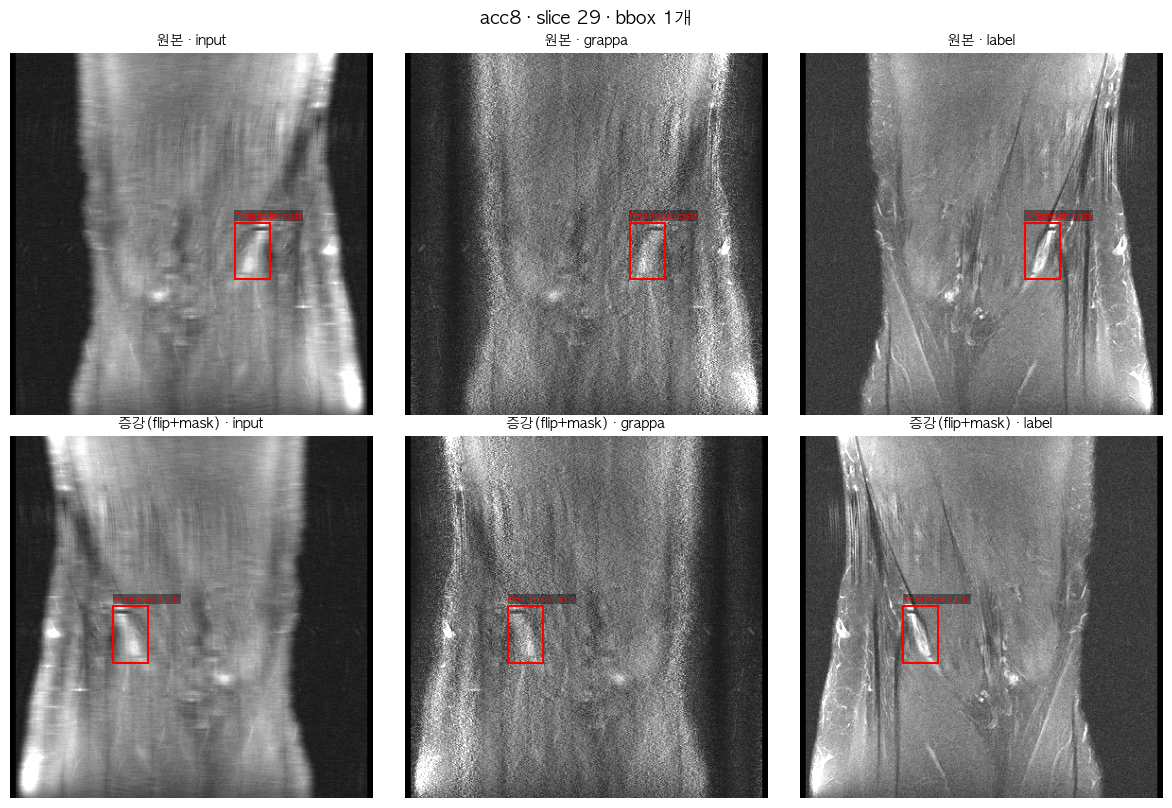

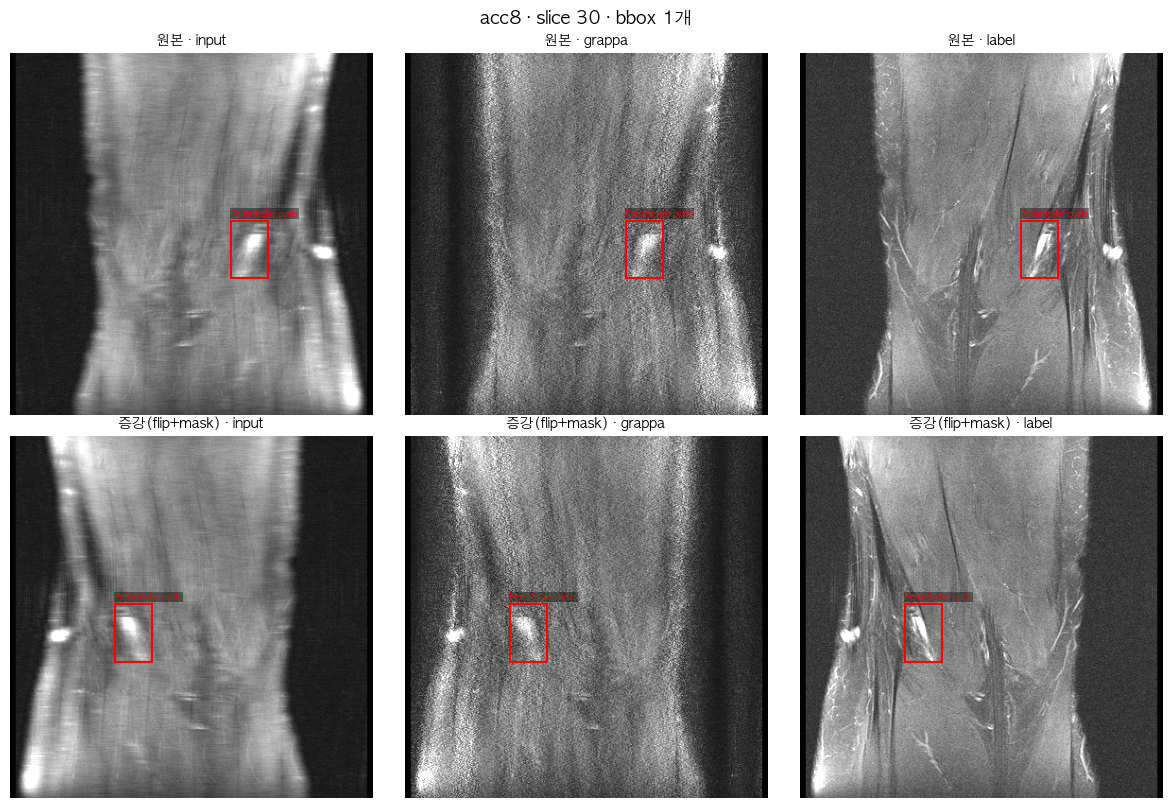

In [3]:
def compare_image_slice(acc, sl):
    oi, _ = paths(acc, False); ai, _ = paths(acc, True)
    with h5py.File(oi) as h:
        o = {k: h[k][sl] for k in IMAGE_KEYS}; oann = load_ann(h).get(sl, [])
    with h5py.File(ai) as h:
        a = {k: h[k][sl] for k in IMAGE_KEYS}; aann = load_ann(h).get(sl, [])
    fig, axes = plt.subplots(2, 3, figsize=(12, 8.2))
    for j, k in enumerate(IMAGE_KEYS):
        vmax = np.percentile(o[k], 99.5)
        axes[0, j].imshow(o[k], cmap="gray", vmax=vmax); axes[0, j].axis("off")
        axes[0, j].set_title(f"원본 · {k.replace('image_','')}", fontsize=10)
        draw_bboxes(axes[0, j], oann)
        axes[1, j].imshow(a[k], cmap="gray", vmax=vmax); axes[1, j].axis("off")
        axes[1, j].set_title(f"증강(flip+mask) · {k.replace('image_','')}", fontsize=10)
        draw_bboxes(axes[1, j], aann)
    fig.suptitle(f"acc{acc} · slice {sl} · bbox {len(oann)}개", fontsize=13)
    fig.tight_layout(); plt.show()

for acc in (4, 8):
    oi, _ = paths(acc, False)
    with h5py.File(oi) as h: slices = sorted(load_ann(h))
    for sl in slices:
        compare_image_slice(acc, sl)

## 3. k-space + mask 비교 — 마스크 증강(ACS 보존 thinning) 확인

k-space 로그 크기(코일 RSS)와 언더샘플 mask를 원본↔증강으로 비교.
증강 쪽은 좌우 flip + 주변부 라인이 추가로 제거된다(중앙 ACS는 유지).

> 참고: 원본 파일의 `kspace`는 마스크 **미적용(full)** 상태로 저장돼 있고 로드 시 `kspace*mask`로
> 언더샘플이 적용된다(`DataTransform`과 동일). 공정한 비교를 위해 여기서도 **각자의 mask를 곱해**
> '모델이 실제 보는 입력'을 그린다.

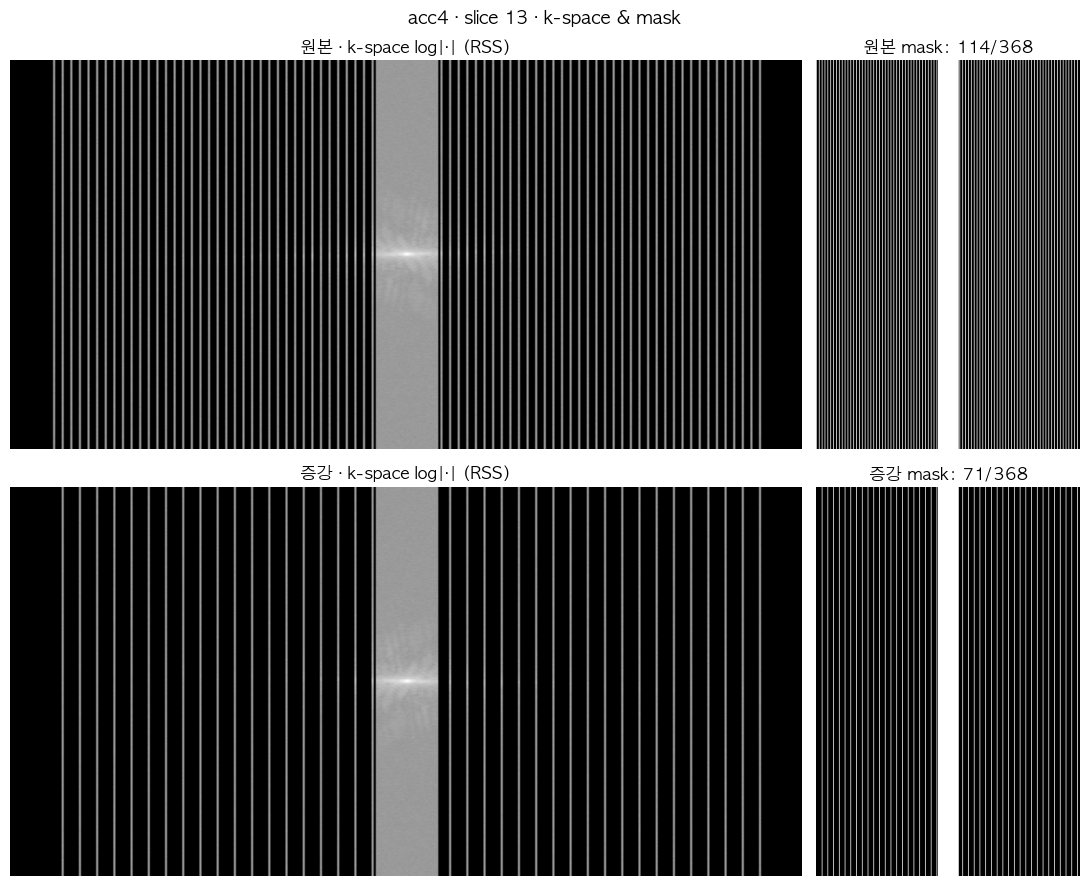

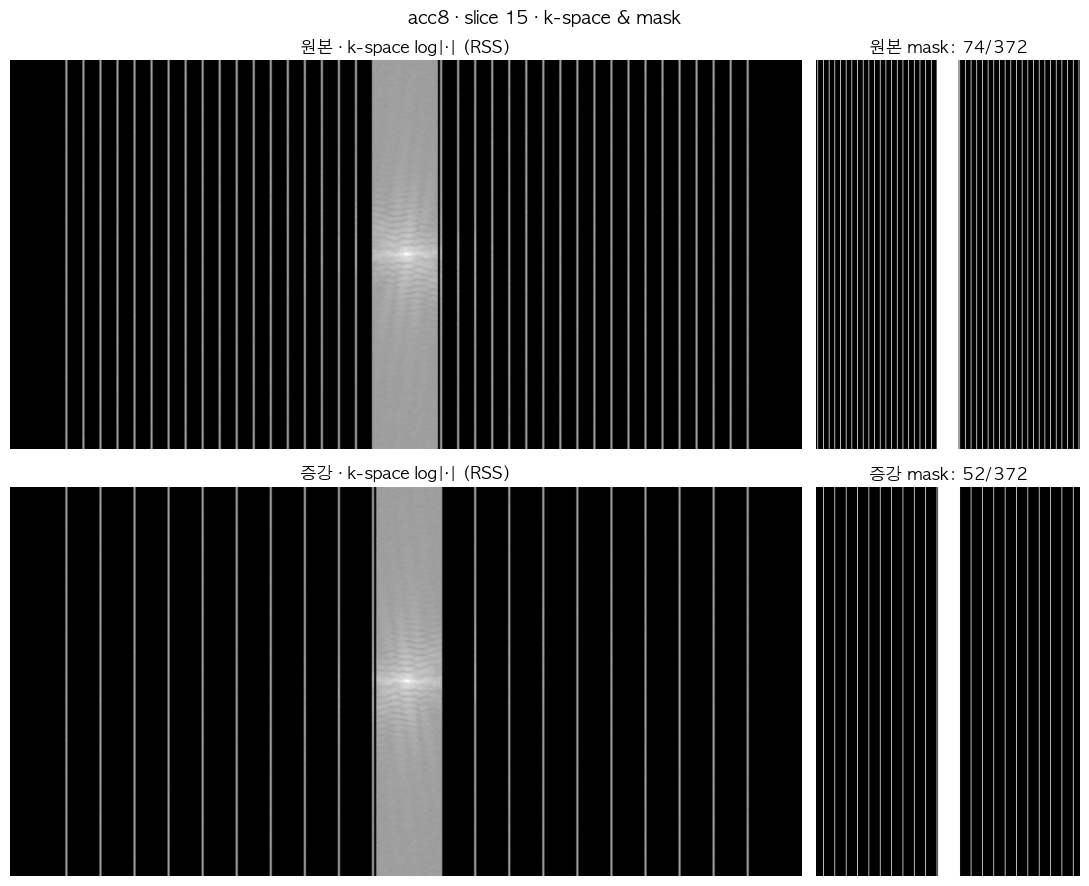

In [4]:
def compare_kspace(acc, sl):
    _, ok = paths(acc, False); _, ak = paths(acc, True)
    def load(p):
        with h5py.File(p) as h:
            m = np.asarray(h["mask"])
            k = h["kspace"][sl] * (m >= 1)          # 모델이 보는 입력 = kspace * mask
        return np.log(np.sqrt((np.abs(k)**2).sum(0)) + 1e-9), m
    ko, mo = load(ok); ka, ma = load(ak)
    fig, axes = plt.subplots(2, 2, figsize=(11, 9),
                             gridspec_kw={"width_ratios": [3, 1]})
    for row, (kl, m, tag) in enumerate([(ko, mo, "원본"), (ka, ma, "증강")]):
        axes[row, 0].imshow(kl, cmap="gray", aspect="auto")
        axes[row, 0].set_title(f"{tag} · k-space log|·| (RSS)"); axes[row, 0].axis("off")
        axes[row, 1].imshow(m[None, :].repeat(40, 0), cmap="gray", aspect="auto")
        axes[row, 1].set_title(f"{tag} mask: {int(m.sum())}/{m.size}"); axes[row, 1].axis("off")
    fig.suptitle(f"acc{acc} · slice {sl} · k-space & mask", fontsize=13)
    fig.tight_layout(); plt.show()

for acc in (4, 8):
    oi, _ = paths(acc, False)
    with h5py.File(oi) as h: sl = min(load_ann(h)) if load_ann(h) else 0
    compare_kspace(acc, sl)

## 4. 정렬 검증 — flip이 픽셀 정확한가

`flip(원본 label) == 증강 label` 이 정확히 0인지, bbox가 병변을 여전히 감싸는지 수치로 확인.

In [5]:
for acc in (4, 8):
    oi, _ = paths(acc, False); ai, _ = paths(acc, True)
    with h5py.File(oi) as ho, h5py.File(ai) as ha:
        sl = min(load_ann(ho))
        L = ho["image_label"][sl]; A = ha["image_label"][sl]
        sc = np.abs(L).mean()
        print(f"acc{acc} slice{sl}:")
        print(f"  flip(원본) vs 증강 label = {np.abs(L[:,::-1]-A).mean()/sc:.2e}  (0이면 픽셀정확)")
        print(f"  원본 vs 증강 label       = {np.abs(L-A).mean()/sc:.3f}  (>0 = 실제로 뒤집힘)")
        ob = load_ann(ho)[sl][0]; ab = load_ann(ha)[sl][0]
        print(f"  bbox x: {ob['x']} -> {ab['x']}  (기대 {384-ob['x']-ob['width']})")

acc4 slice13:
  flip(원본) vs 증강 label = 0.00e+00  (0이면 픽셀정확)
  원본 vs 증강 label       = 0.406  (>0 = 실제로 뒤집힘)
  bbox x: 158 -> 196  (기대 196)
acc8 slice15:
  flip(원본) vs 증강 label = 0.00e+00  (0이면 픽셀정확)
  원본 vs 증강 label       = 0.383  (>0 = 실제로 뒤집힘)
  bbox x: 296 -> 71  (기대 71)
